# Análise Exploratória de Dados SRAG - OpenDataSUS


Projeto de exploração, diagnóstico e limpeza de dados da base SRAG (Síndrome Respiratória Aguda Grave) utilizando dados públicos do OpenDataSUS/DataSUS via API.

In [ ]:
import requests
import pandas as pd
import matplotlib.pyplot as plt
base_url = "https://apidadosabertos.saude.gov.br/vigilancia-e-meio-ambiente/srag-2019-2026"

## Investigação Temporal da API

Foi realizada uma exploração inicial para identificar quais períodos realmente possuíam dados disponíveis.

In [ ]:
import requests
import pandas as pd

# ==========================================
# URL BASE
# ==========================================

base_url = "https://apidadosabertos.saude.gov.br/vigilancia-e-meio-ambiente/srag-2019-2026"

# ==========================================
# ANOS PARA VERIFICAR
# ==========================================

anos = [2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025, 2026]

# ==========================================
# LISTA DOS DATAFRAMES
# ==========================================

lista_df = []

# ==========================================
# BUSCAR DADOS
# ==========================================

for ano in anos:

    print(f"\n========== ANO {ano} ==========")

    for mes in range(1, 13):

        anomes = f"{ano}{mes:02d}"

        url = f"{base_url}?anomes_notific={anomes}&limit=1000&offset=0"

        response = requests.get(url)

        dados = response.json()

        quantidade = len(
            dados['srag_2019_2026']
        )

        # ==========================================
        # SE TIVER DADOS
        # ==========================================

        if quantidade > 0:

            print(
                f"{anomes}: {quantidade} registros"
            )

            # cria dataframe do mês
            df_mes = pd.DataFrame(
                dados['srag_2019_2026']
            )

            # adiciona na lista
            lista_df.append(df_mes)

# ==========================================
# JUNTAR TODOS OS DATAFRAMES
# ==========================================

df = pd.concat(
    lista_df,
    ignore_index=True
)

# ==========================================
# TAMANHO FINAL
# ==========================================

print("\nTamanho final da base:")

print(df.shape)

# ==========================================
# VISUALIZAR
# ==========================================

df.head()


========== ANO 2018 ==========
201812: 1000 registros

========== ANO 2019 ==========
201912: 1000 registros

========== ANO 2020 ==========
202012: 1000 registros

========== ANO 2021 ==========
202112: 1000 registros

========== ANO 2022 ==========

========== ANO 2023 ==========
202301: 1000 registros
202312: 1000 registros

========== ANO 2024 ==========
202412: 1000 registros

========== ANO 2025 ==========
202512: 1000 registros

========== ANO 2026 ==========

Tamanho final da base:
(8000, 194)


,nu_notific,dt_notific,sem_not,dt_sin_pri,sem_pri,sg_uf_not,id_regiona,co_regiona,id_municip,co_mun_not,...,vg_oms,vg_omsout,vg_lin,vg_met,vg_metout,vg_dtres,vg_enc,vg_reinf,vg_codest,reinf
0,315478195042,2018-12-30,02,2019-01-06,02,MG,BELO HORIZONTE,1449,BELO HORIZONTE,310620,...,None,None,None,None,None,None,None,None,None,None
1,315478195276,2018-12-30,01,2019-01-01,01,SP,GVE I CAPITAL,1331,SAO PAULO,355030,...,None,None,None,None,None,None,None,None,None,None
2,315478207219,2018-12-30,01,2018-12-31,01,PE,001,1497,RECIFE,261160,...,None,None,None,None,None,None,None,None,None,None
3,315478211086,2018-12-30,02,2019-01-07,02,SP,GVE XVII CAMPINAS,1342,CAMPINAS,350950,...,None,None,None,None,None,None,None,None,None,None
4,315478212765,2018-12-30,02,2019-01-06,02,PE,004,1499,CARUARU,260410,...,None,None,None,None,None,None,None,None,None,None


## Insight Inicial

Durante a exploração da API, foi identificado que diversos meses retornavam vazios, enquanto alguns anos apresentavam registros apenas em dezembro. Isso sugere possíveis limitações ou inconsistências na disponibilização dos dados públicos pela API.

##Limpeza

In [ ]:

# ==========================================
# 1. REMOVER DUPLICADOS
# ==========================================

df = df.drop_duplicates()

# ==========================================
# 2. REMOVER LINHAS TOTALMENTE VAZIAS
# ==========================================

df = df.dropna(how='all')

# ==========================================
# 3. REMOVER COLUNAS MUITO VAZIAS
# ==========================================

percentual_nulos = df.isnull().mean() * 100

colunas_remover = percentual_nulos[
    percentual_nulos > 85
].index

df = df.drop(columns=colunas_remover)


# ==========================================
# 5. LIMPAR ESPAÇOS EXTRAS
# ==========================================

colunas_texto = df.select_dtypes(include='object').columns

for col in colunas_texto:

    df[col] = df[col].str.strip()

# ==========================================
# 6. TRANSFORMAR "9" EM NULO
# ==========================================

df = df.replace('9', pd.NA)

# ==========================================
# 7. CONVERTER COLUNAS NUMÉRICAS
# ==========================================

for col in df.columns:

    try:
        df[col] = pd.to_numeric(df[col])

    except:
        pass

# ==========================================
# 8. TRATAR IDADES INVÁLIDAS
# ==========================================

if 'nu_idade_n' in df.columns:

    df['nu_idade_n'] = pd.to_numeric(
        df['nu_idade_n'],
        errors='coerce'
    )

    df = df[
        (df['nu_idade_n'] >= 0) &
        (df['nu_idade_n'] <= 120)
    ]

# ==========================================
# 9. PADRONIZAR SEXO
# ==========================================

if 'cs_sexo' in df.columns:

    df['cs_sexo'] = df['cs_sexo'].replace({
        'M': 'Masculino',
        'F': 'Feminino',
        'I': 'Ignorado'
    })

# ==========================================
# 10. RENOMEAR COLUNAS IMPORTANTES
# ==========================================

df = df.rename(columns={

    # identificação
    'nu_notific': 'id_notificacao',

    # datas
    'dt_notific': 'data_notificacao',
    'dt_sin_pri': 'data_primeiros_sintomas',
    'dt_nasc': 'data_nascimento',
    'dt_interna': 'data_internacao',
    'dt_entuti': 'data_entrada_uti',
    'dt_saiduti': 'data_saida_uti',
    'dt_coleta': 'data_coleta',
    'dt_pcr': 'data_pcr',
    'dt_evoluca': 'data_evolucao',
    'dt_encerra': 'data_encerramento',
    'dt_digita': 'data_digitacao',

    # localização
    'sg_uf_not': 'estado_notificacao',
    'id_municip': 'municipio_notificacao',
    'co_mun_not': 'codigo_municipio_notificacao',

    'sg_uf': 'estado_residencia',
    'id_mn_resi': 'municipio_residencia',
    'co_mun_res': 'codigo_municipio_residencia',

    # paciente
    'cs_sexo': 'sexo',
    'nu_idade_n': 'idade',
    'cs_raca': 'raca',
    'cs_escol_n': 'escolaridade',

    # sintomas
    'febre': 'febre',
    'tosse': 'tosse',
    'garganta': 'dor_garganta',
    'dispneia': 'dispneia',
    'saturacao': 'baixa_saturacao',
    'diarreia': 'diarreia',
    'vomito': 'vomito',

    # hospitalização
    'hospital': 'hospitalizado',
    'uti': 'uti',
    'suport_ven': 'suporte_ventilatorio',

    # exames
    'raiox_res': 'resultado_raio_x',
    'pcr_resul': 'resultado_pcr',

    # evolução
    'classi_fin': 'classificacao_final',
    'criterio': 'criterio_confirmacao',
    'evolucao': 'evolucao_caso'
})

# ==========================================
# 2. CONVERTER COLUNAS DE DATA
# ==========================================

colunas_data = [
    'data_notificacao',
    'data_primeiros_sintomas',
    'data_nascimento',
    'data_internacao',
    'data_entrada_uti',
    'data_saida_uti',
    'data_coleta',
    'data_pcr',
    'data_evolucao',
    'data_encerramento',
    'data_digitacao'
]

for col in colunas_data:

    df[col] = pd.to_datetime(
        df[col].astype(str),
        format='%Y-%m-%d',
        errors='coerce'
    )
# ==========================================
# 11. VERIFICAR RESULTADO FINAL
# ==========================================

print(df.info())

# ==========================================
# 12. VISUALIZAR PRIMEIRAS LINHAS
# ==========================================

df.head()

# ==========================================
# 13. SALVAR BASE LIMPA
# ==========================================

df.to_csv(
    'srag_limpo.csv',
    index=False
)

print("Base limpa salva com sucesso!")

<class 'pandas.core.frame.DataFrame'>
Index: 7872 entries, 0 to 7999
Columns: 109 entries, id_notificacao to reinf
dtypes: datetime64[ns](11), float64(70), int64(5), object(23)
memory usage: 6.6+ MB
None
Base limpa salva com sucesso!


##Insights

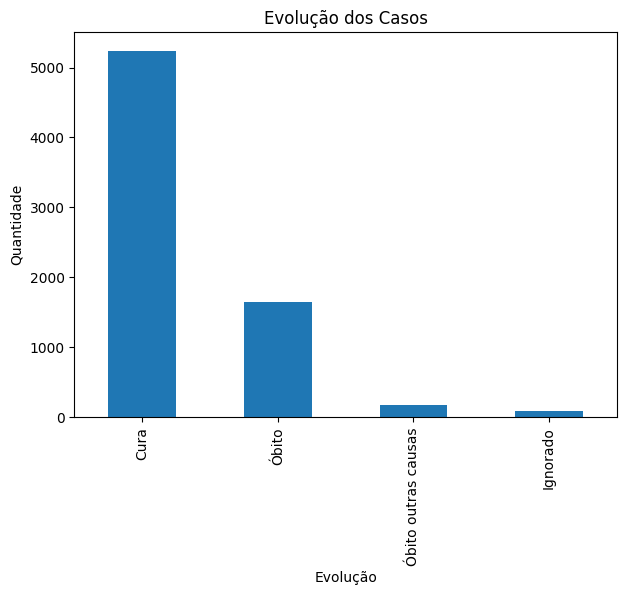

In [ ]:
df['evolucao_caso'] = df['evolucao_caso'].replace({
    1: 'Cura',
    2: 'Óbito',
    3: 'Óbito outras causas',
    9: 'Ignorado'
})

df['evolucao_caso'].value_counts().plot(
    kind='bar',
    figsize=(7,5)
)

plt.title('Evolução dos Casos')
plt.xlabel('Evolução')
plt.ylabel('Quantidade')
plt.show()

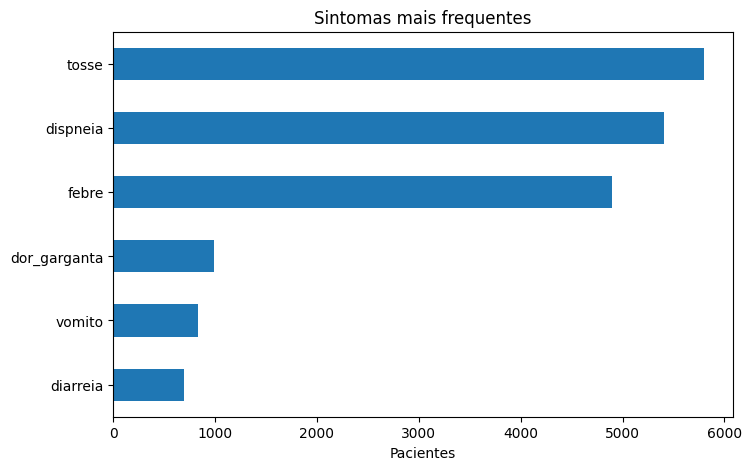

In [ ]:
sintomas = [
    'febre',
    'tosse',
    'dor_garganta',
    'dispneia',
    'diarreia',
    'vomito'
]

frequencia = {}

for sintoma in sintomas:

    frequencia[sintoma] = (
        df[sintoma] == 1
    ).sum()

frequencia
pd.Series(frequencia).sort_values().plot(
    kind='barh',
    figsize=(8,5)
)

plt.title('Sintomas mais frequentes')
plt.xlabel('Pacientes')
plt.show()

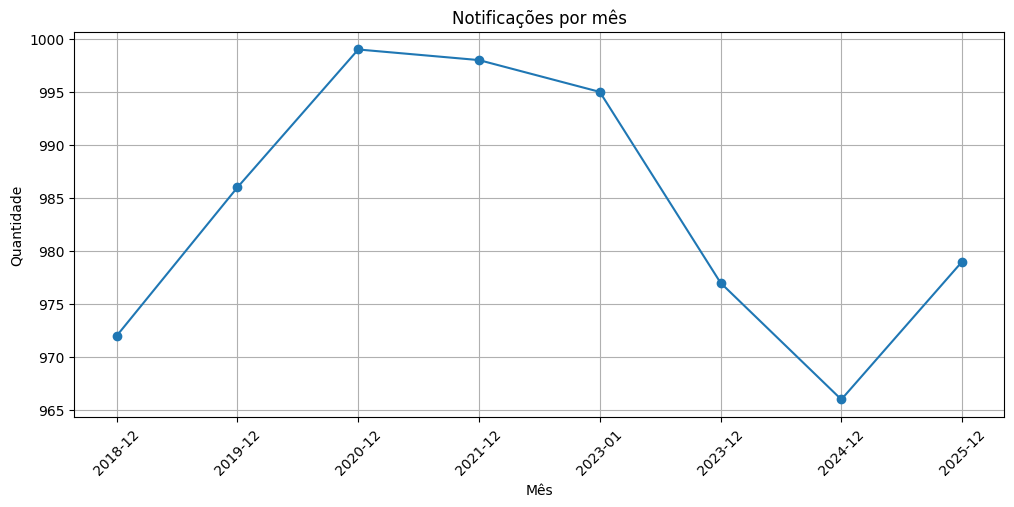

In [ ]:
casos_mes = df.groupby(
    df['data_notificacao'].dt.strftime('%Y-%m')
).size()

casos_mes.plot(
    figsize=(12,5),
    marker='o'
)

plt.title('Notificações por mês')

plt.xlabel('Mês')

plt.ylabel('Quantidade')

plt.xticks(rotation=45)

plt.grid()

plt.show()

## Conclusão



Minha base ainda precisa de uma limpeza e verificação antes de estar totalmente pronta para modelagem e análises mais avançadas.

Durante o consumo da API do DataSUS foram encontradas algumas inconsistências importantes, como:

- muitos valores nulos;
- códigos numéricos sem descrição;
- registros incompletos;
- inconsistências em algumas datas;
- dificuldade para acessar todos os períodos diretamente pela API.

Também foi necessário utilizar filtros específicos de ano e mês para localizar dados de determinados períodos.

Mesmo com essas limitações, após o tratamento básico dos dados foi possível realizar análises relevantes sobre:
- evolução dos casos;
- sintomas mais frequentes;
- distribuição temporal das notificações de SRAG.

A base possui potencial para análises epidemiológicas, porém exige tratamento e validação cuidadosa antes de análises mais avançadas.